In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare, binomtest, norm

files = {
    "Linux urandom": "data/urandom.bin",
    "OpenSSL rand": "data/openssl.bin",
    "Python secrets": "data/python_secrets.bin"
}

random_data = {}

for name, path in files.items():
    with open(path, "rb") as f:
        data = f.read()

    if len(data) < 1048576:
        raise ValueError(f"{path} contains less than 1 MiB")

    random_data[name] = np.frombuffer(data, dtype=np.uint8)

    print(f"{name}: {len(data)} bytes")

print("All files loaded successfully.")

/home/mnit/.local/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/home/mnit/.local/lib/python3.10/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (
/tmp/ipykernel_7813/3802469359.py:3: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


Linux urandom: 1048576 bytes
OpenSSL rand: 1048576 bytes
Python secrets: 1048576 bytes
All files loaded successfully.


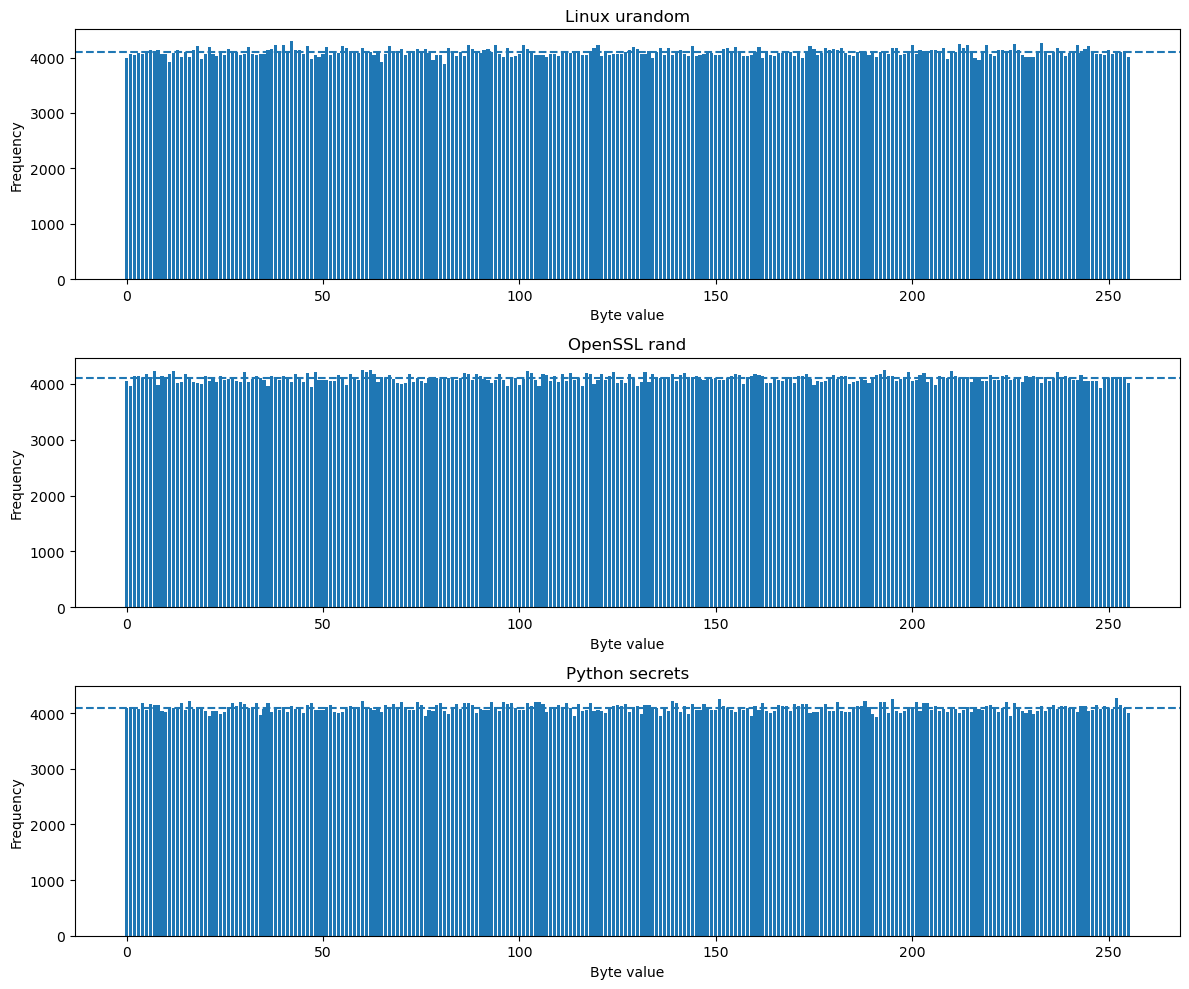

,Generator,Chi-square,P-value,Minimum frequency,Maximum frequency
0,Linux urandom,267.848145,0.277915,3881,4294
1,OpenSSL rand,256.641113,0.459369,3931,4253
2,Python secrets,273.882812,0.198859,3938,4276


In [2]:
results = []

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

for ax, (name, data) in zip(axes, random_data.items()):
    frequencies = np.bincount(data, minlength=256)
    expected = len(data) / 256

    statistic, p_value = chisquare(frequencies)

    results.append({
        "Generator": name,
        "Chi-square": statistic,
        "P-value": p_value,
        "Minimum frequency": frequencies.min(),
        "Maximum frequency": frequencies.max()
    })

    ax.bar(range(256), frequencies)
    ax.axhline(expected, linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Byte value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

display(pd.DataFrame(results))

In [3]:
bit_results = []

for name, data in random_data.items():
    bits = np.unpackbits(data)
    ones = int(bits.sum())
    zeros = len(bits) - ones

    test = binomtest(ones, n=len(bits), p=0.5)

    bit_results.append({
        "Generator": name,
        "Zeros": zeros,
        "Ones": ones,
        "Percentage of ones": 100 * ones / len(bits),
        "P-value": test.pvalue
    })

display(pd.DataFrame(bit_results))

,Generator,Zeros,Ones,Percentage of ones,P-value
0,Linux urandom,4193859,4194749,50.005305,0.758887
1,OpenSSL rand,4193626,4194982,50.008082,0.639901
2,Python secrets,4196191,4192417,49.977505,0.192680


In [4]:
correlation_results = []

for name, data in random_data.items():
    correlation = np.corrcoef(
        data[:-1].astype(float),
        data[1:].astype(float)
    )[0, 1]

    correlation_results.append({
        "Generator": name,
        "Serial correlation": correlation
    })

display(pd.DataFrame(correlation_results))

,Generator,Serial correlation
0,Linux urandom,0.000779
1,OpenSSL rand,-0.001821
2,Python secrets,-0.001577


In [5]:
pattern_results = []

for name, data in random_data.items():
    adjacent_equal = int(np.sum(data[1:] == data[:-1]))

    blocks = data[:len(data) // 16 * 16].reshape(-1, 16)
    _, counts = np.unique(blocks, axis=0, return_counts=True)

    duplicate_blocks = int(np.sum(counts - 1))

    pattern_results.append({
        "Generator": name,
        "Adjacent equal bytes": adjacent_equal,
        "Duplicate 16-byte blocks": duplicate_blocks
    })

display(pd.DataFrame(pattern_results))

,Generator,Adjacent equal bytes,Duplicate 16-byte blocks
0,Linux urandom,4331,0
1,OpenSSL rand,4163,0
2,Python secrets,4096,0


In [6]:
runs_results = []

for name, data in random_data.items():
    bits = np.unpackbits(data).astype(np.uint8)

    n = len(bits)
    p = bits.mean()

    runs = 1 + np.count_nonzero(bits[1:] != bits[:-1])

    if abs(p - 0.5) >= 2 / np.sqrt(n):
        runs_results.append({
            "Generator": name,
            "Observed Runs": runs,
            "Expected Runs": np.nan,
            "Z-score": np.nan,
            "P-value": np.nan,
            "Result": "Precondition not satisfied"
        })
        continue

    expected = 1 + 2 * n * p * (1 - p)

    variance = (
        2 * n * p * (1 - p)
        * (2 * n * p * (1 - p) - 1)
        / (n - 1)
    )

    z = (runs - expected) / np.sqrt(variance)
    p_value = 2 * norm.sf(abs(z))

    runs_results.append({
        "Generator": name,
        "Observed Runs": runs,
        "Expected Runs": expected,
        "Z-score": z,
        "P-value": p_value,
        "Result": (
            "Potential deviation"
            if p_value < 0.05
            else "No significant deviation detected"
        )
    })

runs_table = pd.DataFrame(runs_results)
display(runs_table)

,Generator,Observed Runs,Expected Runs,Z-score,P-value,Result
0,Linux urandom,4196755,4.194305e+06,1.691841,0.090676,No significant deviation detected
1,OpenSSL rand,4193477,4.194305e+06,-0.571686,0.567534,No significant deviation detected
2,Python secrets,4192707,4.194304e+06,-1.102887,0.270076,No significant deviation detected


In [7]:
summary = pd.DataFrame({
    "Generator": list(random_data.keys()),
    "File Size (bytes)": [
        len(data) for data in random_data.values()
    ],
    "Percentage of Ones": [
        100 * np.unpackbits(data).mean()
        for data in random_data.values()
    ],
    "Serial Correlation": [
        np.corrcoef(
            data[:-1].astype(float),
            data[1:].astype(float)
        )[0, 1]
        for data in random_data.values()
    ],
    "Adjacent Equal Bytes": [
        int(np.sum(data[1:] == data[:-1]))
        for data in random_data.values()
    ]
})

display(summary)

,Generator,File Size (bytes),Percentage of Ones,Serial Correlation,Adjacent Equal Bytes
0,Linux urandom,1048576,50.005305,0.000779,4331
1,OpenSSL rand,1048576,50.008082,-0.001821,4163
2,Python secrets,1048576,49.977505,-0.001577,4096
